# Does compiling the compressed model improve inference?

**Eager execution** is ordinary PyTorch execution: Python calls tensor operations
as the model runs. `torch.compile` prepares optimized code that later calls can
reuse. Here we ask whether it works with our TensorLy-Torch models, whether it
reduces repeated-inference latency, and how the compiled compressed models compare
with a compiled dense baseline.

We use the same trained weights and compression settings under both execution
methods. Compilation changes execution, not the chosen factor ranks. Synthetic
inputs check output agreement and timing; they do not measure task accuracy or
runtime memory.

This notebook runs the experiment. It adapts the [PyTorch tutorial](https://docs.pytorch.org/tutorials/intermediate/torch_compile_full_example.html)
to our CPU setup: `backend="inductor", mode="default"`, no CUDA timing or graphs,
and no assertion that compilation must be faster. First-use latency is reported
separately because the first forward normally triggers compilation.

## 1. Set up the environment and fixed inputs

Select the existing **TensorLy model compression** kernel. This run reuses Python
3.12.3, PyTorch 2.5.1+cpu, and the existing numerical packages without installing
anything. GCC/G++ 13.3.0 is available. A small independent toolchain check already
compiled and executed a tensor calculation using a separate temporary cache.

The code below creates a new result directory and a private Inductor cache. It
never clears shared caches. The private cache starts empty, but this does not make
startup measurements completely cold: process initialization and operating-system
caches can be warm, and later models can reuse artifacts from earlier models.
Choose a new output name and save notebook edits before rerunning from a fresh kernel.

In [1]:
import csv
import hashlib
import importlib.metadata
import json
import os
from pathlib import Path
import shutil
import statistics
import subprocess
import sys
import tempfile
import time
import traceback
from datetime import datetime, timezone

repository = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / "tltorch").is_dir())
example_directory = repository / "examples/model_compression"
output_directory = example_directory / "results/torch_compile_run_001"
output_directory.mkdir(parents=True, exist_ok=False)
diagnostic_directory = output_directory / "diagnostics"
diagnostic_directory.mkdir()

cache_directory = Path.home() / ".cache/tltorch-model-compression"
compiler_cache_parent = cache_directory / "torch-compile"
compiler_cache_parent.mkdir(parents=True, exist_ok=True)
compiler_cache = Path(tempfile.mkdtemp(prefix="inductor-", dir=compiler_cache_parent))
previous_compiler_cache_setting = os.environ.get("TORCHINDUCTOR_CACHE_DIR")
os.environ["TORCHINDUCTOR_CACHE_DIR"] = str(compiler_cache)
os.environ.setdefault("TORCH_HOME", str(cache_directory / "torch"))

import matplotlib.pyplot as plt
import torch
import torch.backends.opt_einsum as torch_opt_einsum
import tensorly as tl
from torch._inductor import config as inductor_config
from torch._inductor.cpp_builder import get_cpp_compiler
from IPython.display import Markdown, display

sys.path.insert(0, str(repository))
import tltorch
from tltorch import compress_model
from examples.model_compression import experiment
from examples.model_compression import opt_einsum_comparison
from examples.model_compression import torch_compile_comparison as comparison

assert torch.__version__ == "2.5.1+cpu"
assert Path(tltorch.__file__).resolve() == repository / "tltorch/__init__.py"
torch_opt_einsum.enabled = False
tl.set_backend("pytorch")
tl.tenalg.set_backend("core")

def show_table(columns, rows):
    """Render a small table without adding a dataframe dependency."""
    lines = [" | ".join(columns), " | ".join("---" for _ in columns)]
    lines.extend(" | ".join(str(value) for value in row) for row in rows)
    display(Markdown("\n".join(lines)))

def save_json(filename, contents):
    (output_directory / filename).write_text(json.dumps(contents, indent=2, allow_nan=False) + "\n")


We use three fixed seeded inputs for correctness and the first one for all timing.
Each tensor is a batch of one RGB image, shaped `(1, 3, 224, 224)`. Models and inputs
use CPU float32, four PyTorch threads, and one inter-op thread.

opt_einsum stays **disabled throughout**, including loading, conversion, compilation,
checks, and timing. TensorLy stays on its PyTorch / `core` backends with its separate
plugin inactive. The backend checks below verify those conditions rather than
assuming that package installation determines execution.

In [2]:
settings = {
    "device": "cpu", "dtype": "float32", "threads": 4, "interop_threads": 1,
    "conversion_seed": 2026, "input_seeds": [2027, 2028, 2029],
    "batch_size": 1, "rounds": 4, "warmup": 20, "repeats": 100,
    "rtol": 1e-4, "atol": 1e-5, "compiler_backend": "inductor", "compiler_mode": "default",
}
device = experiment.configure_runtime(settings["device"], settings["threads"])
inputs = [torch.randn(1, 3, 224, 224, dtype=torch.float32, device=device,
                      generator=torch.Generator(device=device).manual_seed(seed))
          for seed in settings["input_seeds"]]
timing_input = inputs[0]
initial_backend = comparison.checked_backend_settings()
assert initial_backend["threads"] == 4 and initial_backend["interop_threads"] == 1
initial_cache = comparison.cache_inventory(compiler_cache)
assert initial_cache["files"] == 0

compiler_command = get_cpp_compiler()
compiler = {
    "command": compiler_command, "path": shutil.which(compiler_command),
    "version": subprocess.check_output([compiler_command, "--version"], text=True),
    "compile_threads": inductor_config.compile_threads,
    "fx_graph_cache": inductor_config.fx_graph_cache,
    "suppress_errors": torch._dynamo.config.suppress_errors,
    "dynamo_cache_size_limit": torch._dynamo.config.cache_size_limit,
}
environment = experiment.environment_info()
environment["python_executable"] = sys.executable
environment["packages"] = {distribution.metadata["Name"]: distribution.version
                           for distribution in importlib.metadata.distributions()}
environment["working_tree_status"] = subprocess.check_output(
    ["git", "status", "--short", "--untracked-files=all"], cwd=repository, text=True)
environment["helper_sha256"] = {Path(module.__file__).name: experiment.file_sha256(module.__file__)
                                for module in (experiment, comparison, opt_einsum_comparison)}
notebook_path = example_directory / "torch_compile_comparison.ipynb"
notebook_on_disk = json.loads(notebook_path.read_text())
notebook_code = "\n\n".join("".join(cell["source"]) for cell in notebook_on_disk["cells"]
                            if cell["cell_type"] == "code")
environment["notebook_code_sha256"] = hashlib.sha256(notebook_code.encode()).hexdigest()
input_hashes_before = [hashlib.sha256(data.numpy().tobytes()).hexdigest() for data in inputs]
save_json("setup.json", {"settings": settings, "environment": environment, "compiler": compiler,
                         "backend": initial_backend, "initial_cache": initial_cache,
                         "compiler_cache": str(compiler_cache), "input_sha256": input_hashes_before})
print("Environment:", sys.executable)
print("CPU:", environment["cpu"])
print("Compiler:", compiler["version"].splitlines()[0])
print("Actual backend:", initial_backend)
print("Private compiler cache:", compiler_cache)


Environment: /home/rafael_magaldi/.cache/tltorch-model-compression/venv/bin/python
CPU: Intel(R) Core(TM) Ultra 9 285H
Compiler: g++ (Ubuntu 13.3.0-6ubuntu2~24.04.1) 13.3.0
Actual backend: {'available': False, 'enabled': False, 'strategy': None, 'tensorly_backend': 'pytorch', 'tensorly_tenalg_backend': 'core', 'tensorly_default_einsum': True, 'tensorly_plugin_inactive': True, 'tensorly_plugin_cache_entries': 0, 'threads': 4, 'interop_threads': 1, 'matmul_precision': 'highest', 'deterministic_algorithms': True, 'mkldnn_enabled': True, 'autocast_enabled': False}
Private compiler cache: /home/rafael_magaldi/.cache/tltorch-model-compression/torch-compile/inductor-6p5sjmn6


## 2. Load the trained baseline and construct two compressed copies

We load cached `ResNet18_Weights.IMAGENET1K_V1`; no weights or dataset are downloaded.
Construction and conversion happen outside inference mode. Each compressed model
starts from the untouched dense baseline, using the public `compress_model` API.

The two Tucker convolutions keep spatial ranks fixed at the 3×3 kernel dimensions.
The BlockTT classifier splits 512 inputs into `(8, 8, 8)` and 1,000 outputs into
`(10, 10, 10)`. Targets 0.75 and 0.50 request approximate fractions of each selected
weight's parameters, not whole-model storage fractions.

In [3]:
comparison.checked_backend_settings()
torch.manual_seed(settings["conversion_seed"])
baseline, preprocessing = experiment.load_baseline(device, allow_download=False)
baseline_fingerprint = experiment.model_fingerprint(baseline)
models = {"dense": baseline}
reports = {}
layers_by_variant = {}

for name, fraction in (("fraction_0.75", 0.75), ("fraction_0.50", 0.50)):
    layers = {
        "layer4.0.conv2": {
            "factorization": "Tucker", "rank": fraction, "fixed_rank_modes": "spatial",
        },
        "layer4.1.conv2": {
            "factorization": "Tucker", "rank": fraction, "fixed_rank_modes": "spatial",
        },
        "fc": {
            "factorization": "BlockTT", "rank": fraction,
            "in_tensorized_features": (8, 8, 8), "out_tensorized_features": (10, 10, 10),
        },
    }
    torch.manual_seed(settings["conversion_seed"])
    models[name], reports[name] = compress_model(baseline, layers, implementation="factorized")
    models[name].eval()
    layers_by_variant[name] = layers
    assert experiment.model_fingerprint(baseline) == baseline_fingerprint
    print(name, "actual ranks:", [layer["actual_rank"] for layer in reports[name]["replacements"]])

assert all(not module.training for model in models.values() for module in model.modules())
model_fingerprints_before = {name: experiment.model_fingerprint(model) for name, model in models.items()}
model_ids = {name: id(model) for name, model in models.items()}
save_json("compression_reports.json", reports)


fraction_0.75 actual ranks: [(390, 390, 3, 3), (390, 390, 3, 3), (1, 68, 68, 1)]


fraction_0.50 actual ranks: [(310, 310, 3, 3), (310, 310, 3, 3), (1, 56, 56, 1)]


## 3. Check what the compiler can capture

A **graph break** is a point where execution leaves a captured region and continues
in ordinary Python/PyTorch. A partially compiled model can still work and improve
latency, but it is not one fully captured graph.

First we use PyTorch 2.5's `torch._dynamo.explain` to record captured operations and
break locations. This is a diagnostic pass, not an Inductor benchmark. In this
version it resets Dynamo's in-process capture cache, so **all explain passes happen
before we create any compiled callable**. Later first-use checks establish that
Inductor actually produced executable regions. Detailed logs go to `diagnostics/`.

In [4]:
capture = {}
for name, model in models.items():
    comparison.checked_backend_settings()
    with comparison.diagnostic_log(diagnostic_directory / f"{name}_capture.log"):
        try:
            capture[name] = comparison.explain_capture(model, timing_input)
        except Exception:
            capture[name] = {"error": traceback.format_exc()}
    print(name, "capture graphs:", capture[name].get("graph_count"),
          "graph breaks:", capture[name].get("graph_break_count"),
          "diagnostic failed:", "error" in capture[name])
assert {name: experiment.model_fingerprint(model) for name, model in models.items()} == model_fingerprints_before
save_json("capture_diagnostics.json", capture)


dense capture graphs: 1 graph breaks: 0 diagnostic failed: False


fraction_0.75 capture graphs: 13 graph breaks: 12 diagnostic failed: False


fraction_0.50 capture graphs: 13 graph breaks: 12 diagnostic failed: False


`torch.compile(model)` returns a callable using that model and its parameters.
It does not create another independently compressed model. The visible calls below
compile only the forward computations, after conversion is finished.

Wrapper creation alone does not prove compilation succeeded. We time the **first
forward**, including compilation and execution, and record generated kernels,
captured graphs, and cache activity. This is first-use latency, not pure compiler
time. Each first-use record also includes the private cache state at that point.
A successful region may call existing PyTorch/library operators; that is different
from a Python graph break. The cache inventory lists such external calls.

Compiler errors remain enabled. A failed model is recorded and excluded from
compiled comparisons; supported models can continue. No eager substitute is
presented as an Inductor result.

In [5]:
compiled_models = {}
first_use = {}
for name, model in models.items():
    comparison.checked_backend_settings()
    before_cache = comparison.cache_inventory(compiler_cache)
    before = comparison.compiler_snapshot()
    record = {"cache_before": before_cache, "compiler_before": before}
    first_started = None
    with comparison.diagnostic_log(diagnostic_directory / f"{name}_compile.log"):
        try:
            setup_started = time.perf_counter()
            compiled = torch.compile(model, backend="inductor", mode="default")
            record["wrapper_setup_seconds"] = time.perf_counter() - setup_started
            assert compiled._orig_mod is model
            assert all(left is right for left, right in zip(model.parameters(), compiled.parameters()))
            with torch.inference_mode():
                first_started = time.perf_counter()
                first_output = compiled(timing_input)
                record["first_use_seconds"] = time.perf_counter() - first_started
            after = comparison.compiler_snapshot()
            evidence = any(after[key] > before[key] for key in
                           ("generated_kernels", "inductor_cache_hits", "inductor_cache_misses"))
            record["inductor_activity_observed"] = evidence
            if not evidence:
                raise RuntimeError("Forward succeeded but no Inductor activity was observed; inspect diagnostics.")
            record["status"] = "compiled"
            record["error"] = None
            compiled_models[name] = compiled
        except Exception:
            record["status"] = "unavailable"
            record["error"] = traceback.format_exc()
            if first_started is not None and "first_use_seconds" not in record:
                record["failed_first_use_seconds"] = time.perf_counter() - first_started
    record["compiler_after"] = comparison.compiler_snapshot()
    record["compiler_changes"] = comparison.compiler_changes(before, record["compiler_after"])
    record["counters_after"] = {category: dict(values) for category, values in comparison.counters.items()}
    record["cache_after"] = comparison.cache_inventory(compiler_cache)
    first_use[name] = record
    print(name, record["status"], "first-use seconds:", record.get("first_use_seconds"),
          "compiler activity:", record["compiler_changes"])
save_json("first_use.json", first_use)


dense compiled first-use seconds: 6.15569454999968 compiler activity: {'frames_started': 1, 'unique_graphs': 1, 'inductor_cache_misses': 1, 'generated_kernels': 39}


fraction_0.75 compiled first-use seconds: 23.249194670999714 compiler activity: {'frames_started': 32, 'unique_graphs': 12, 'inductor_cache_misses': 12, 'generated_kernels': 53, 'guard_failures': 6}


fraction_0.50 compiled first-use seconds: 6.319110212000851 compiler activity: {'frames_started': 4, 'unique_graphs': 3, 'inductor_cache_misses': 3, 'generated_kernels': 6, 'guard_failures': 4}


## 4. Verify outputs and prepare every model before timing

For each supported model, compare eager and compiled outputs on all three seeded
inputs with the fixed float32 tolerance **rtol=1e-4, atol=1e-5**. A difference must
fit `1e-5 + 1e-4 × abs(eager_output)`. Different multiplication/fusion orders may
change rounding, so bitwise equality is not required.

A failed comparison is retained and prevents compiled timing for that model; we
do not loosen tolerances. Successful models receive 20 preparation warm-ups each,
before the timing rounds start. Compilation-triggering forwards, correctness,
warm-up, and timing all use evaluation and inference mode.

In [6]:
agreement = {}
preparation = {}
for name, model in models.items():
    compiled = compiled_models.get(name)
    if compiled is None:
        agreement[name] = {"status": "unavailable", "reason": first_use[name]["error"]}
        continue
    comparison.checked_backend_settings()
    before = comparison.compiler_snapshot()
    with comparison.diagnostic_log(diagnostic_directory / f"{name}_verification.log"):
        try:
            checks = comparison.compare_outputs(model, compiled, inputs,
                                                 rtol=settings["rtol"], atol=settings["atol"])
            agreement[name] = {"status": "passed" if all(check["passed"] for check in checks) else "failed",
                               "checks": checks}
            if agreement[name]["status"] != "passed":
                del compiled_models[name]
            else:
                with torch.inference_mode():
                    for _ in range(settings["warmup"]):
                        model(timing_input)
                        compiled(timing_input)
        except Exception:
            agreement[name] = {"status": "failed", "error": traceback.format_exc()}
            del compiled_models[name]
    after = comparison.compiler_snapshot()
    preparation[name] = {"compiler_before": before, "compiler_after": after,
                         "compiler_changes": comparison.compiler_changes(before, after)}
show_table(["Model", "Input seed", "Maximum absolute difference", "Passed"],
           [[name, settings["input_seeds"][check["input_index"]],
             f"{check['max_absolute_difference']:.9g}", check["passed"]]
            for name, result in agreement.items() for check in result.get("checks", [])])
save_json("output_agreement.json", agreement)


Model | Input seed | Maximum absolute difference | Passed
--- | --- | --- | ---
dense | 2027 | 2.62260437e-06 | True
dense | 2028 | 3.33786011e-06 | True
dense | 2029 | 2.98023224e-06 | True
fraction_0.75 | 2027 | 3.81469727e-06 | True
fraction_0.75 | 2028 | 4.29153442e-06 | True
fraction_0.75 | 2029 | 3.09944153e-06 | True
fraction_0.50 | 2027 | 2.74181366e-06 | True
fraction_0.50 | 2028 | 2.74181366e-06 | True
fraction_0.50 | 2029 | 2.98023224e-06 | True

Now make three more untimed calls per supported model, after all models have been
prepared. Counter changes reveal new capture, compilation, or guard failures on
these repeated same-shape calls. A **guard** checks an assumption used by compiled
code, such as a tensor's shape; a failed guard may require another compilation.

The timing helper also checks these counters outside each block. If compiler
activity appears, it keeps the samples but marks that block invalid for a table
of latency after compilation. No profiling hooks or diagnostic logging remain
active during timing; only the built-in counter snapshots are read around blocks.

**Observed compiler behavior in `results/torch_compile_run_001/`.**
The capture diagnostic found one graph and zero
breaks for dense, and 13 graphs / 12 breaks for each compressed model. FactorList
iteration inside TensorLy's `multi_mode_dot`, and unpacking the BlockTT factors for
`einsum`, prevented complete capture. The actual Inductor log also recorded a
recoverable `DataDependentOutputException` at
`tltorch/factorized_layers/factorized_convolution.py:193`, where the stride tensor
is converted to a Python list. PyTorch inserted a break and left that surrounding
Python code eager; inner tensor operations still compiled. Errors were not suppressed.

All first forwards executed Inductor-generated regions. Their kernel-counter
increases were 39, 53, and 6 in construction order. The latter two figures include
reuse/specialization effects and are not standalone coverage percentages. Generated
wrappers also call existing convolution, matrix-multiplication, and batched
matrix-multiplication kernels; those external calls are not themselves Python
graph breaks. The BlockTT `einsum` appears in a captured tensor region.

There was additional compilation during preparation: the dense verification phase
added three ResNet regions after guards detected differing layer types or
intermediate shapes in shared forward code. Thus the initial capture counts are
not a count of regions executed by every later call, and first-use time is not
the complete preparation cost. The subsequent same-shape probe and all timing
blocks recorded **no further capture, compilation, or guard-failure counter changes**.


In [7]:
repeat_checks = {}
for name, compiled in compiled_models.items():
    before = comparison.compiler_snapshot()
    with comparison.diagnostic_log(diagnostic_directory / f"{name}_repeat.log"):
        with torch.inference_mode():
            for _ in range(3):
                compiled(timing_input)
    after = comparison.compiler_snapshot()
    repeat_checks[name] = {"compiler_before": before, "compiler_after": after,
                           "compiler_changes": comparison.compiler_changes(before, after)}
    print(name, "repeated-call compiler changes:", repeat_checks[name]["compiler_changes"])
assert {name: experiment.model_fingerprint(model) for name, model in models.items()} == model_fingerprints_before
save_json("preparation.json", {"correctness_and_warmup": preparation, "repeated_calls": repeat_checks})
show_table(["Model", "Capture graphs", "Graph breaks", "First-use seconds", "Agreement", "Ready for timing"],
           [[name, capture[name].get("graph_count", "unavailable"),
             capture[name].get("graph_break_count", "unavailable"),
             first_use[name].get("first_use_seconds", "unavailable"),
             agreement[name]["status"], name in compiled_models] for name in models])


dense repeated-call compiler changes: {}
fraction_0.75 repeated-call compiler changes: {}
fraction_0.50 repeated-call compiler changes: {}


Model | Capture graphs | Graph breaks | First-use seconds | Agreement | Ready for timing
--- | --- | --- | --- | --- | ---
dense | 1 | 0 | 6.15569454999968 | passed | True
fraction_0.75 | 13 | 12 | 23.249194670999714 | passed | True
fraction_0.50 | 13 | 12 | 6.319110212000851 | passed | True

## 5. Measure paired whole-model inference

All three eager models and every supported compiled callable are ready. Four
rounds run in this same process. Rounds 1 and 3 measure eager then compiled;
rounds 2 and 4 reverse that order. The model order rotates each round, and each
model's two blocks stay adjacent.

Each block uses **20 warm-ups and 100 timed forwards** on the same batch-one input.
The existing CPU timing helper measures completed forwards in milliseconds.
Loading, conversion, compilation setup, checks, and data preparation stay outside
the repeated-inference measurements. We check model fingerprints after each round.

In [8]:
blocks = comparison.measure_rounds(models, compiled_models, timing_input,
                                   rounds=settings["rounds"], warmup=settings["warmup"], repeats=settings["repeats"])
rows = comparison.paired_results(blocks)
model_fingerprints_after = {name: experiment.model_fingerprint(model) for name, model in models.items()}
input_hashes_after = [hashlib.sha256(data.numpy().tobytes()).hexdigest() for data in inputs]
assert model_fingerprints_after == model_fingerprints_before
assert input_hashes_after == input_hashes_before
assert {name: id(model) for name, model in models.items()} == model_ids
assert comparison.checked_backend_settings() == initial_backend
save_json("timing_blocks.json", blocks)
print("Invalid timing blocks:", [block["block"] for block in blocks if not block["valid_after_compilation"]])
print("All model parameters, buffers, and inputs remained unchanged.")


Round 1: dense complete


Round 1: fraction_0.75 complete


Round 1: fraction_0.50 complete


Round 2: fraction_0.75 complete


Round 2: fraction_0.50 complete


...

Round 3: fraction_0.75 complete


Round 4: dense complete


Round 4: fraction_0.75 complete


Round 4: fraction_0.50 complete


Invalid timing blocks: []
All model parameters, buffers, and inputs remained unchanged.


## 6. Compare every round

Brackets show each block's 25th and 75th percentiles: the central half of its
100 samples, not a confidence interval across independent runs. **Speedup = eager
median / compiled median**; values above one favor compiled execution.

Also compare each compiled compressed model with the compiled dense baseline in
the same round. That ratio is **compressed compiled latency / dense compiled
latency**: above one means the compressed model took longer. A speedup relative to
its own eager execution does not necessarily make it faster than compiled dense.

In [9]:
def latency_text(row, condition):
    if row[f"{condition}_status"] != "ok":
        return row[f"{condition}_status"]
    return (f"{row[f'{condition}_median_ms']:.3f} "
            f"[{row[f'{condition}_p25_ms']:.3f}, {row[f'{condition}_p75_ms']:.3f}]")

def ratio_text(value):
    return "unavailable" if value is None else f"{value:.3f}×"

show_table(["Round", "Model", "First", "Eager ms [p25, p75]", "Compiled ms [p25, p75]",
            "Eager / compiled", "Compiled / compiled dense"],
           [[row["round"], row["model"], row["first_condition"], latency_text(row, "eager"),
             latency_text(row, "compiled"), ratio_text(row["speedup"]),
             ratio_text(row["compiled_vs_dense_latency_ratio"])] for row in rows])
print("All latencies are milliseconds per batch of one.")


Round | Model | First | Eager ms [p25, p75] | Compiled ms [p25, p75] | Eager / compiled | Compiled / compiled dense
--- | --- | --- | --- | --- | --- | ---
1 | dense | eager | 20.883 [20.768, 21.008] | 18.570 [18.388, 18.884] | 1.125× | 1.000×
1 | fraction_0.75 | eager | 25.213 [25.070, 25.412] | 24.970 [24.846, 25.197] | 1.010× | 1.345×
1 | fraction_0.50 | eager | 23.659 [23.557, 23.810] | 22.150 [22.084, 22.308] | 1.068× | 1.193×
2 | fraction_0.75 | compiled | 13.392 [12.919, 25.086] | 25.103 [24.880, 25.337] | 0.533× | 2.578×
2 | fraction_0.50 | compiled | 12.302 [12.157, 12.483] | 11.792 [11.559, 22.150] | 1.043× | 1.211×
2 | dense | compiled | 10.619 [10.466, 10.788] | 9.738 [9.585, 10.117] | 1.090× | 1.000×
3 | fraction_0.50 | eager | 12.410 [12.099, 12.730] | 12.100 [11.826, 12.280] | 1.026× | 1.217×
3 | dense | eager | 10.722 [10.540, 10.960] | 9.940 [9.823, 10.179] | 1.079× | 1.000×
3 | fraction_0.75 | eager | 25.241 [25.015, 25.424] | 25.363 [25.146, 25.557] | 0.995× | 2.552×
4 | dense | compiled | 20.798 [20.719, 20.924] | 18.449 [18.308, 18.574] | 1.127× | 1.000×
4 | fraction_0.75 | compiled | 25.320 [25.100, 25.577] | 25.210 [24.923, 25.404] | 1.004× | 1.366×
4 | fraction_0.50 | compiled | 23.734 [23.556, 23.891] | 22.143 [22.024, 22.310] | 1.072× | 1.200×

All latencies are milliseconds per batch of one.


The plot keeps all four rounds visible, with the same latency scale for the three
models. The summary takes the median of the four per-round speedup ratios, with
their range. It does not pool all samples or choose a fastest round. First-use
latencies stay separate from this plot of repeated inference.

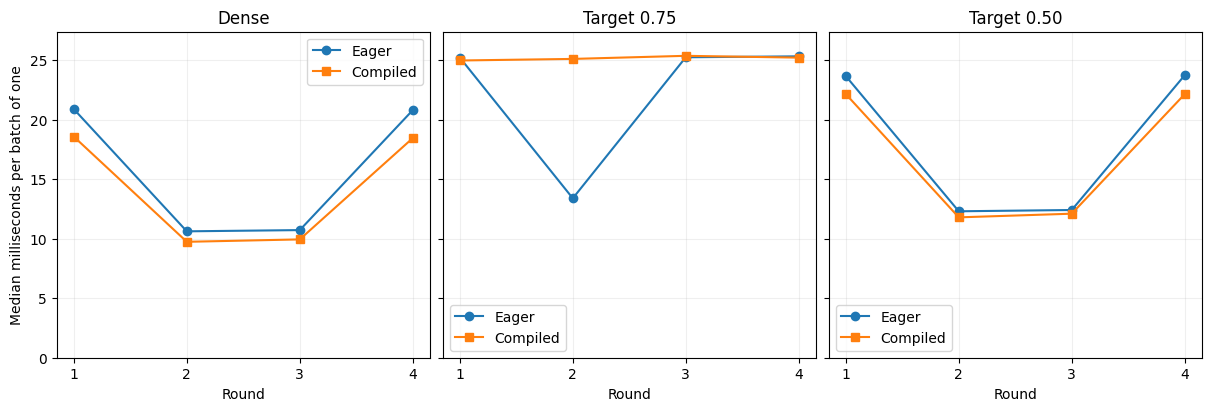

dense: median of 4 per-round ratios 1.107×; range 1.079–1.127×
fraction_0.75: median of 4 per-round ratios 1.000×; range 0.533–1.010×
fraction_0.50: median of 4 per-round ratios 1.056×; range 1.026–1.072×


In [10]:
labels = {"dense": "Dense", "fraction_0.75": "Target 0.75", "fraction_0.50": "Target 0.50"}
figure, axes = plt.subplots(1, 3, figsize=(12, 4), sharey=True, constrained_layout=True)
for axis, name in zip(axes, models):
    selected = sorted((row for row in rows if row["model"] == name), key=lambda row: row["round"])
    for condition, marker in (("eager", "o"), ("compiled", "s")):
        values = [row[f"{condition}_median_ms"] for row in selected]
        if any(value is not None for value in values):
            axis.plot([row["round"] for row in selected], values, marker=marker, label=condition.title())
    axis.set_title(labels[name])
    axis.set_xlabel("Round")
    axis.set_xticks(range(1, settings["rounds"] + 1))
    axis.grid(alpha=0.2)
    axis.legend()
largest_median = max(row[f"{condition}_median_ms"] for row in rows
                     for condition in ("eager", "compiled") if row[f"{condition}_median_ms"] is not None)
axes[0].set_ylim(0, largest_median * 1.08)
axes[0].set_ylabel("Median milliseconds per batch of one")
plt.show()

for name in models:
    ratios = [row["speedup"] for row in rows if row["model"] == name and row["speedup"] is not None]
    if ratios:
        print(f"{name}: median of {len(ratios)} per-round ratios {statistics.median(ratios):.3f}×; "
              f"range {min(ratios):.3f}–{max(ratios):.3f}×")
    else:
        print(name, "no valid compiled comparison")


## 7. Interpret the executed results

The written observations in this notebook describe the saved run in
`results/torch_compile_run_001/`. Rerunning the cells updates tables and plots,
but does not update these observations. Review them separately against any
new results before drawing conclusions.

**Compilation ran successfully, with partial capture of the factorized models.**
All nine eager/compiled output checks passed the fixed tolerance. Maximum absolute
differences across the three inputs were 3.34e-6 for dense, 4.29e-6 for target 0.75,
and 2.98e-6 for target 0.50. Model parameters, buffers, ranks, and inputs remained
unchanged. No whole-model execution was unavailable, but the graph breaks described
above mean the compressed cases combine compiled regions with ordinary Python.

First-use latency was **6.156 s for dense, 23.249 s for target 0.75, and 6.319 s for
target 0.50**. These include execution and compilation, with diagnostic logging
active. The private cache started empty; later variants reused code and already
initialized compiler machinery. Dense also needed additional specialization during
untimed verification. These figures are not isolated cold compiler costs or the
entire preparation time.

For repeated inference, dense was faster with compilation in all four pairs:
speedups ranged from **1.079× to 1.127×**, with a median of four ratios of **1.107×**.
Target 0.50 also improved in every pair: **1.026×–1.072×**, median **1.056×**.
Target 0.75 had **no dependable improvement**: three pairs were near one, while
round 2 had a 0.533× ratio. Its median ratio of 1.000× would hide that unstable pair
if we omitted the individual rounds.

**Absolute CPU timings changed substantially even without recompilation.** Dense
eager medians were about 20.8 ms in rounds 1 and 4 and 10.6–10.7 ms in rounds 2 and 3;
compiled dense moved from about 18.5 ms to 9.7–9.9 ms. The target-0.75 eager block
in round 2 spanned 12.919–25.086 ms between its quartiles. Target-0.50 compiled in
that round spanned 11.559–22.150 ms. This variation also affected the controls.
Its cause was not measured; CPU frequency or competing activity are possible
explanations, not established causes. No fastest round was selected.

Every compiled compressed model was slower than compiled dense in the same round.
The target-0.50 latency ratio was **1.193×–1.217×**; target 0.75 ranged from
**1.345× to 2.578×**, with the large ratios crossing different timing regimes.
These across-model measurements are separated by other blocks, so treat them
especially cautiously when timing regimes change. Less stored weight does not
establish a faster compiled model.

**Recommendation:** compilation is a usable optional execution method here, with
modest and directionally consistent benefits for dense and target 0.50 after
preparation. It is not supported as a universal default for this experiment:
target 0.75 showed no reliable benefit, startup took seconds, and absolute CPU
latency remained unstable. The current main experiment is unchanged. These four
rounds do not establish deployment speedups, GPU behavior, or performance at other
batch sizes, dtypes, ranks, or software versions.

The comparison measures no new task accuracy or runtime-memory savings. Storage
reports cover registered model tensors, excluding compiler code and workspace.
The plot's shared vertical range was corrected after execution using the saved
samples; no timing was repeated. `presentation.json` distinguishes that source
update from the notebook code that originally produced the measurements.


## 8. Save the measurements and provenance

Keep the per-round CSV, all samples, first-use records, output checks, conversion
reports, capture diagnostics, and detailed compiler logs. Early cells already save
completed checks so a later blocker does not erase useful evidence.

The final configuration records exact packages and compiler, code hashes, seeds,
actual backend/thread settings, cache conditions, repository state, and unchanged
model/input fingerprints. Cache binaries stay outside the repository. The result
directory was created exclusively at the start; an existing run is never reused.

In [11]:
from torchvision.models import ResNet18_Weights
weights = ResNet18_Weights.IMAGENET1K_V1
weight_file = Path(torch.hub.get_dir()) / "checkpoints" / weights.url.rsplit("/", 1)[-1]
configuration = {
    "purpose": "Synthetic-input eager versus Inductor inference; no task-accuracy or runtime-memory measurement",
    "settings": settings, "environment": environment, "compiler": compiler,
    "weights": {"identifier": "ResNet18_Weights.IMAGENET1K_V1", "url": weights.url,
                "sha256": experiment.file_sha256(weight_file)},
    "layers": layers_by_variant, "implementation": "factorized",
    "input_shape": list(timing_input.shape), "timing_units": "milliseconds per batch of one",
    "backend_before": initial_backend, "backend_after": comparison.checked_backend_settings(),
    "model_fingerprints_before": model_fingerprints_before, "model_fingerprints_after": model_fingerprints_after,
    "input_hashes_before": input_hashes_before, "input_hashes_after": input_hashes_after,
    "compiler_cache": {"path": str(compiler_cache), "initial": initial_cache,
                       "final": comparison.cache_inventory(compiler_cache),
                       "previous_environment_value": previous_compiler_cache_setting,
                       "note": "New private directory; no shared caches cleared. Not a claim of completely cold startup."},
    "compiler_snapshot_after_timing": comparison.compiler_snapshot(),
    "supported_compiled_models": list(compiled_models),
    "summary_method": "Median of per-round ratios; no pooling or fastest-round selection",
    "completed_utc": datetime.now(timezone.utc).isoformat(),
}
save_json("configuration.json", configuration)
with (output_directory / "results.csv").open("w", newline="") as stream:
    writer = csv.DictWriter(stream, fieldnames=list(rows[0]), lineterminator="\n")
    writer.writeheader()
    for row in rows:
        writer.writerow({key: f"{value:.6f}" if isinstance(value, float) else value for key, value in row.items()})
figure.savefig(output_directory / "comparison.png", dpi=160, bbox_inches="tight")
print("Saved this comparison to:", output_directory)


Saved this comparison to: /home/rafael_magaldi/Documents/infq-tensorly-torch-model-compression/examples/model_compression/results/torch_compile_run_001
